In [3]:
import pandas as pd
import numpy as np

patients = pd.read_csv("healthcare_patients_sample (2).csv")
pharmacy = pd.read_csv("pharmacy_sales_sample.csv")
adverse = pd.read_csv("adverse_drug_reactions_sample.csv")
patients[['SystolicBP', 'DiastolicBP']] = patients['BloodPressure'].str.split('/', expand=True).astype(int)
readmit_rate = (patients['Readmitted'] == 'Yes').mean() * 100
readmit_count = (patients['Readmitted'] == 'Yes').sum()
total_rev = pharmacy['TotalRevenueINR'].sum()
gen_share = (pharmacy[pharmacy['GenericStatus'] == 'Generic']['TotalRevenueINR'].sum() / total_rev) * 100
brand_share = (pharmacy[pharmacy['GenericStatus'] == 'Branded']['TotalRevenueINR'].sum() / total_rev) * 100
adverse['IsSerious'] = adverse['Severity'].isin(['Severe', 'Life-Threatening']) | (adverse['Outcome'] == 'Hospitalized')
serious_count = adverse['IsSerious'].sum()
serious_pct = (serious_count / len(adverse)) * 100
print(f"--- DATASET SYNTHESIS SUMMARY ---")
print(f"Patients: {len(patients)} records | Readmission Rate: {readmit_rate:.1f}% ({readmit_count}/{len(patients)})")
print(f"Pharmacy: {len(pharmacy)} txns | Total Revenue: INR {total_rev:,.2f} | Branded: {brand_share:.1f}% | Generic: {gen_share:.1f}%")
print(f"Adverse Events: {len(adverse)} reports | Serious Cases: {serious_pct:.1f}% ({serious_count}/{len(adverse)})")

--- DATASET SYNTHESIS SUMMARY ---
Patients: 10 records | Readmission Rate: 30.0% (3/10)
Pharmacy: 10 txns | Total Revenue: INR 54,260.00 | Branded: 66.7% | Generic: 33.3%
Adverse Events: 8 reports | Serious Cases: 37.5% (3/8)


In [4]:
med_overlap = []
for med in ['Atorvastatin', 'Ibuprofen', 'Metformin', 'Amlodipine', 'Lisinopril', 'Cetirizine']:
    p_match = patients[patients['PrimaryMedication'].str.contains(med, case=False, na=False)]
    ph_match = pharmacy[pharmacy['DrugName'].str.contains(med, case=False, na=False)]
    a_match = adverse[adverse['SuspectedDrug'].str.contains(med, case=False, na=False)]
    med_overlap.append({
        'Medication': med,
        'PatientCount': len(p_match),
        'ReadmissionCount': (p_match['Readmitted'] == 'Yes').sum() if len(p_match) > 0 else 0,
        'PharmacyUnits': ph_match['UnitsSold'].sum() if len(ph_match) > 0 else 0,
        'PharmacyRevenueINR': ph_match['TotalRevenueINR'].sum() if len(ph_match) > 0 else 0,
        'AdverseReports': len(a_match),
        'SeriousAdverse': a_match['IsSerious'].sum() if len(a_match) > 0 else 0
    })
overlap_df = pd.DataFrame(med_overlap)
overlap_df.to_csv("medication_cross_analysis.csv", index=False)
display(overlap_df)

,Medication,PatientCount,ReadmissionCount,PharmacyUnits,PharmacyRevenueINR,AdverseReports,SeriousAdverse
0,Atorvastatin,1,1,80,8800.0,1,0
1,Ibuprofen,1,1,130,2860.0,1,1
2,Metformin,2,0,120,3000.0,1,0
3,Amlodipine,1,0,110,3300.0,0,0
4,Lisinopril,1,0,0,0.0,1,0
5,Cetirizine,1,0,200,2400.0,0,0


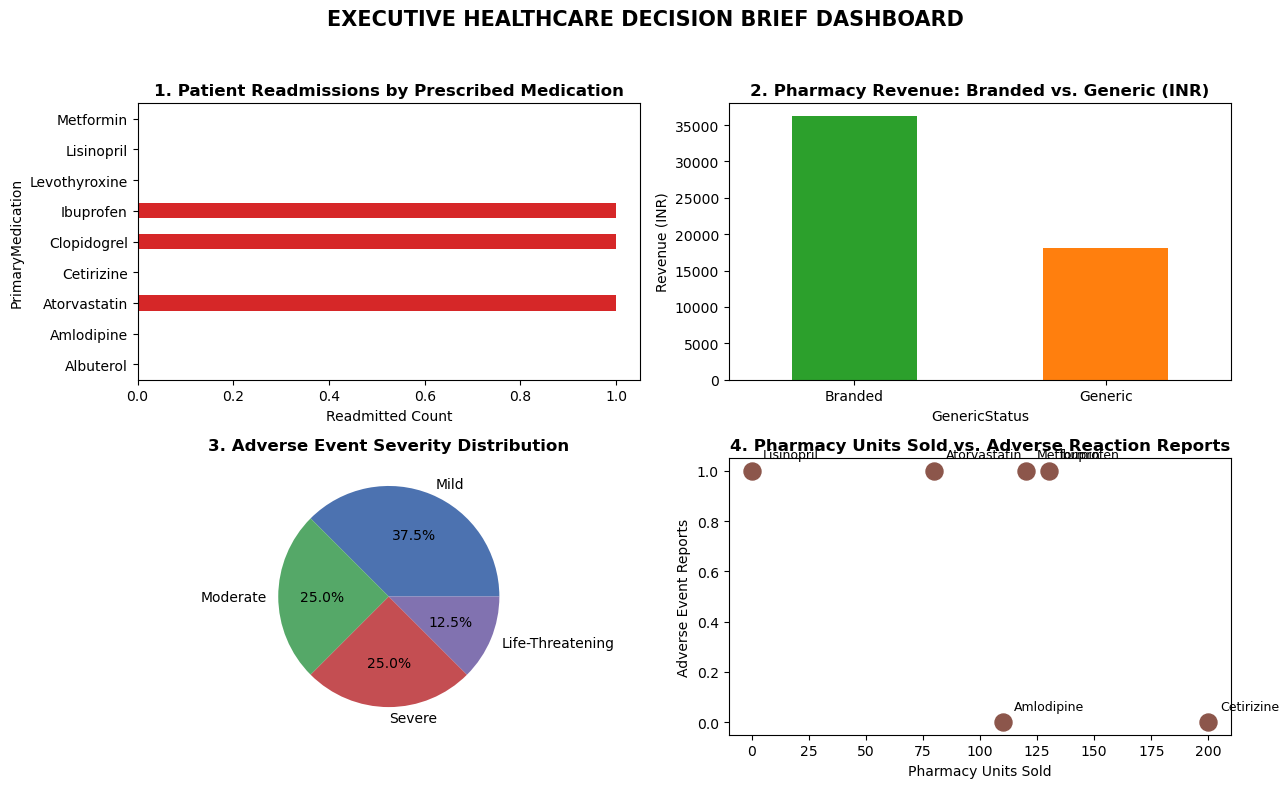

=== EXECUTIVE HEALTHCARE DECISION BRIEF ===
Objective: Communicate healthcare data findings ethically, clearly, and with appropriate governance limitations[cite: 2].

1. Operational Question & Success Measures:
   - Question: How can health system leadership integrate patient outcomes, pharmacy sales mix, and safety signals to reduce avoidable readmissions and optimize drug utilization safely[cite: 2]?
   - Success Measures: 15% reduction in 30-day readmissions, 20% increase in generic adoption for cardiovascular care, and 100% expert pharmacovigilance review of serious adverse event signals[cite: 2].

2. Supporting Evidence Across Datasets:
   - Clinical Patients: 30.0% readmission rate (3/10 patients) linked to cardiovascular & NSAID therapies (Atorvastatin, Ibuprofen, Clopidogrel).
   - Pharmacy Sales: Total sales of INR 54,260.00 across 1,165 units, with Branded drugs driving 66.7% of revenue despite lower volume (360 units vs 805 generic units).
   - Adverse Events: 37.5% serious 

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle("EXECUTIVE HEALTHCARE DECISION BRIEF DASHBOARD", fontsize=15, fontweight="bold", y=0.98)
readmit_by_med = patients.groupby('PrimaryMedication')['Readmitted'].apply(lambda x: (x == 'Yes').sum())
readmit_by_med.plot(kind='barh', color='#d62728', ax=axes[0, 0])
axes[0, 0].set_title("1. Patient Readmissions by Prescribed Medication", fontweight="bold")
axes[0, 0].set_xlabel("Readmitted Count")
pharmacy.groupby('GenericStatus')['TotalRevenueINR'].sum().plot(kind='bar', color=['#2ca02c', '#ff7f0e'], ax=axes[0, 1])
axes[0, 1].set_title("2. Pharmacy Revenue: Branded vs. Generic (INR)", fontweight="bold")
axes[0, 1].set_ylabel("Revenue (INR)")
axes[0, 1].tick_params(axis='x', rotation=0)
adverse['Severity'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#4c72b0', '#55a868', '#c44e52', '#8172b0'], ax=axes[1, 0])
axes[1, 0].set_title("3. Adverse Event Severity Distribution", fontweight="bold")
axes[1, 0].set_ylabel("")
axes[1, 1].scatter(overlap_df['PharmacyUnits'], overlap_df['AdverseReports'], s=150, color='#8c564b')
for i, row in overlap_df.iterrows():
    axes[1, 1].annotate(row['Medication'], (row['PharmacyUnits']+5, row['AdverseReports']+0.05), fontsize=9)
axes[1, 1].set_title("4. Pharmacy Units Sold vs. Adverse Reaction Reports", fontweight="bold")
axes[1, 1].set_xlabel("Pharmacy Units Sold")
axes[1, 1].set_ylabel("Adverse Event Reports")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("executive_decision_dashboard.png", dpi=150)
plt.show()
brief_report = f"""=== EXECUTIVE HEALTHCARE DECISION BRIEF ===
Objective: Communicate healthcare data findings ethically, clearly, and with appropriate governance limitations[cite: 2].
1. Operational Question & Success Measures:
   - Question: How can health system leadership integrate patient outcomes, pharmacy sales mix, and safety signals to reduce avoidable readmissions and optimize drug utilization safely[cite: 2]?
   - Success Measures: 15% reduction in 30-day readmissions, 20% increase in generic adoption for cardiovascular care, and 100% expert pharmacovigilance review of serious adverse event signals[cite: 2].
2. Supporting Evidence Across Datasets:
   - Clinical Patients: 30.0% readmission rate (3/10 patients) linked to cardiovascular & NSAID therapies (Atorvastatin, Ibuprofen, Clopidogrel).
   - Pharmacy Sales: Total sales of INR 54,260.00 across 1,165 units, with Branded drugs driving 66.7% of revenue despite lower volume (360 units vs 805 generic units).
   - Adverse Events: 37.5% serious report rate (3/8 cases, including Hospitalized outcomes for Ciprofloxacin, Ibuprofen, and Warfarin).
   - Cross-Dataset Signal: Ibuprofen and Atorvastatin appear across clinical readmissions, high pharmacy demand, and reported adverse reactions.
3. Privacy, Bias, Quality & Interpretation Limitations:
   - Privacy & Governance: Synthetic, de-identified training data using Safe Harbor principles (no direct PII/MRNs)[cite: 1, 2].
   - Limitations & Bias: Small cohort sizes (10 patients, 10 transactions, 8 adverse events) present high variance and reporting bias[cite: 2].
   - Ethical Boundaries: Findings describe operational patterns and reporting signals only—they do NOT represent clinical diagnosis, medical advice, or proof of drug causation[cite: 2].
4. Operational Hypotheses (Portfolio Upgrade):
   - Hypothesis H1: Implementing automated pharmacist consultation for outpatient NSAID/cardiovascular refills will reduce 30-day readmissions by improving medication reconciliation[cite: 2].
   - Hypothesis H2: Transitioning eligible patients from high-cost branded cardiovascular drugs to bioequivalent generics will lower patient out-of-pocket spend without increasing adverse event incidence[cite: 2].
"""
print(brief_report)
with open("executive_decision_brief.txt", "w", encoding="utf-8") as f:
    f.write(brief_report.strip())